# Morocco Electricity Consumption and Environmental Factors Analysis
**AnalystLab Africa | Week 5 | Track 1: Data Analytics**
**Author:** Godfrey Miracle

In [1]:
## Task 1: Dataset Understanding and Inspection

In [11]:
import pandas as pd

In [12]:
df = pd.read_csv('powerconsumption.csv')

In [13]:
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 4.3 MB


In [15]:
df.shape

(52416, 9)

In [16]:
df.describe()

,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000,52416.000000
mean,18.810024,68.259518,1.959489,182.696614,75.028022,32344.970564,21042.509082,17835.406218
std,5.815476,15.551177,2.348862,264.400960,124.210949,7130.562564,5201.465892,6622.165099
min,3.247000,11.340000,0.050000,0.004000,0.011000,13895.696200,8560.081466,5935.174070
25%,14.410000,58.310000,0.078000,0.062000,0.122000,26310.668692,16980.766032,13129.326630
50%,18.780000,69.860000,0.086000,5.035500,4.456000,32265.920340,20823.168405,16415.117470
75%,22.890000,81.400000,4.915000,319.600000,101.000000,37309.018185,24713.717520,21624.100420
max,40.010000,94.800000,6.483000,1163.000000,936.000000,52204.395120,37408.860760,47598.326360


In [17]:
df.duplicated()

0        False
1        False
2        False
3        False
4        False
         ...  
52411    False
52412    False
52413    False
52414    False
52415    False
Length: 52416, dtype: bool

In [20]:
# Count missing values across the whole table.

print("Missing values:", df.isna().sum().sum())

# Count rows that are exact copies of another row.

print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


In [21]:
# Convert Datetime from text to a real date-time (month/day/year order)
df["Datetime"] = pd.to_datetime(df["Datetime"], format="%m/%d/%Y %H:%M")
df["Datetime"].dtype

dtype('<M8[us]')

In [22]:
# Show the first and last reading to see the period covered
print("First reading:", df["Datetime"].min())
print("Last reading: ", df["Datetime"].max())

First reading: 2017-01-01 00:00:00
Last reading:  2017-12-30 23:50:00


In [23]:
# Time gap between each reading and the one before it
gaps = df["Datetime"].diff().dropna()
gaps.value_counts()

Datetime
0 days 00:10:00    52415
Name: count, dtype: int64

In [24]:
# Check for duplicate timestamps and that rows are in time order
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())
print("In time order:", df["Datetime"].is_monotonic_increasing)

Duplicate timestamps: 0
In time order: True


In [25]:
# Compare actual rows with the number of 10-minute slots expected
expected = pd.date_range(df["Datetime"].min(), df["Datetime"].max(), freq="10min")
print("Expected readings:", len(expected))
print("Actual readings:", len(df))

Expected readings: 52416
Actual readings: 52416


In [26]:
# Load the data dictionary and show the full descriptions
dd = pd.read_csv("powerconsumption_datadictionary.csv", encoding="utf-8-sig")
pd.set_option("display.max_colwidth", None)
dd

,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases diffuse into the broader atmosphere
5,DiffuseFlows,The measurement of how much emissions gases diffuse into the local atmosphere
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Power Zone 1
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Power Zone 2
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Power Zone 3


In [27]:
# Average of the two diffuse flow columns for each hour of the day
df.groupby(df["Datetime"].dt.hour)[["GeneralDiffuseFlows", "DiffuseFlows"]].mean().round(1)

,GeneralDiffuseFlows,DiffuseFlows
Datetime,,
0,0.1,0.1
1,0.1,0.1
2,0.1,0.1
3,0.1,0.1
4,0.1,0.1
5,0.1,0.1
6,5.5,4.7
7,47.0,39.2
8,145.5,109.3


In [28]:
# Total of all three zones across the whole year, under two readings of the unit
zones = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
total = df[zones].sum().sum()
print("If each value is kWh used in 10 min:", round(total / 1e9, 2), "TWh")
print("If each value is average kW (energy = kW x 1/6 hour):", round(total / 6 / 1e6), "GWh")

If each value is kWh used in 10 min: 3.73 TWh
If each value is average kW (energy = kW x 1/6 hour): 622 GWh


**Note on the consumption unit.** The data dictionary gives the unit as kilowatt-hours, but the size of the values suggests they are average power in kW. If each 10-minute value were kWh, the three zones would add up to about 3.73 TWh in a year, roughly 7.6% of Morocco's national demand, which is too high for one area. Read as kW, the total is about 622 GWh, which is more believable. Because the file cannot confirm the unit, values are reported as recorded and no absolute energy totals are given. Patterns, rankings and correlations are the same under either reading.

## Task 2: Data Cleaning and Preparation
### 2.1 Create time-based columns

In [29]:
# Create Year, Month, Day, Hour, Day of week and Date columns
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["Day"] = df["Datetime"].dt.day
df["Hour"] = df["Datetime"].dt.hour
df["Day_of_Week"] = df["Datetime"].dt.day_name()
df["Date"] = df["Datetime"].dt.date
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Year,Month,Day,Hour,Day_of_Week,Date
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,2017,1,1,0,Sunday,2017-01-01
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,2017,1,1,0,Sunday,2017-01-01
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,2017,1,1,0,Sunday,2017-01-01
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,2017,1,1,0,Sunday,2017-01-01
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,2017,1,1,0,Sunday,2017-01-01


### 2.2 Unusual or extreme consumption values

In [30]:
# Summary statistics for the three zone columns
zones = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
df[zones].describe()

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000
mean,32344.970564,21042.509082,17835.406218
std,7130.562564,5201.465892,6622.165099
min,13895.696200,8560.081466,5935.174070
25%,26310.668692,16980.766032,13129.326630
50%,32265.920340,20823.168405,16415.117470
75%,37309.018185,24713.717520,21624.100420
max,52204.395120,37408.860760,47598.326360


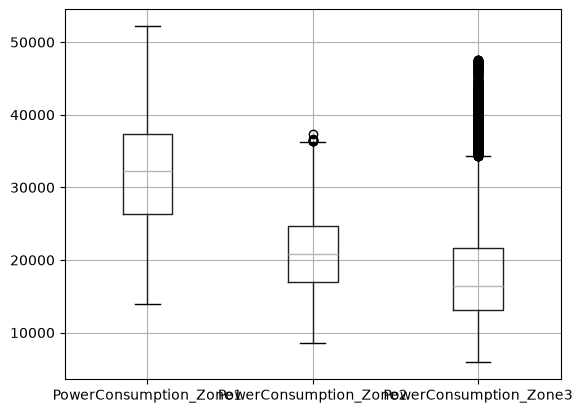

In [31]:
# Boxplot of the three zones to spot unusual values
import matplotlib.pyplot as plt
df[zones].boxplot()
plt.show()

### 2.3 Investigating the high Zone 3 readings

In [32]:
# Show the 10 highest Zone 3 readings with their dates
df.nlargest(10, "PowerConsumption_Zone3")[["Datetime", "PowerConsumption_Zone3"]]

,Datetime,PowerConsumption_Zone3
29497,2017-07-24 20:10:00,47598.32636
29929,2017-07-27 20:10:00,47598.32636
29784,2017-07-26 20:00:00,47580.25105
29785,2017-07-26 20:10:00,47507.94979
29786,2017-07-26 20:20:00,47441.67364
29930,2017-07-27 20:20:00,47435.64854
29496,2017-07-24 20:00:00,47429.62343
29498,2017-07-24 20:20:00,47405.52301
29783,2017-07-26 19:50:00,47291.04603
29353,2017-07-23 20:10:00,47278.99582


In [33]:
# Count Zone 3 readings above 30,000 in each month
high = df[df["PowerConsumption_Zone3"] > 30000]
high["Month"].value_counts().sort_index()

Month
6     143
7    1644
8     797
Name: count, dtype: int64

### 2.3 Investigating the high Zone 3 readings
Zone 3 has many readings far above its typical level. All readings above 30,000 fall in June, July and August and the ten highest are all from late July at around 8 PM, across several different days. This points to a genuine summer evening peak, not sensor error. No values are removed or changed. Zone 1 has no unusual values and Zone 2 only a handful.

### 2.4 Save the cleaned dataset

In [34]:
# Save the cleaned data with the new time columns to a CSV file
df.to_csv("powerconsumption_cleaned.csv", index=False)
print("Saved. Rows and columns:", df.shape)

Saved. Rows and columns: (52416, 15)


## Task 3: Electricity Consumption Analysis
### 3.1 Average consumption by zone

In [35]:
# Average consumption of each zone, highest first
df[zones].mean().sort_values(ascending=False).round(0)

PowerConsumption_Zone1    32345.0
PowerConsumption_Zone2    21043.0
PowerConsumption_Zone3    17835.0
dtype: float64

In [36]:
# Standard deviation divided by the average shows how variable each zone is
(df[zones].std() / df[zones].mean()).round(2)

PowerConsumption_Zone1    0.22
PowerConsumption_Zone2    0.25
PowerConsumption_Zone3    0.37
dtype: float64

Zone 1 has the highest average consumption (32,345) and Zone 3 the lowest (17,835). Zone 3 is also the most variable relative to its own level (0.37), which fits the summer peaks found in Task 2.

### 3.2 Hourly consumption pattern

In [37]:
# Average consumption of each zone for every hour of the day
hourly = df.groupby("Hour")[zones].mean().round(0)
hourly

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.0,19692.0,18657.0
1,27566.0,17765.0,16971.0
2,26293.0,16730.0,15981.0
3,25338.0,16053.0,15239.0
4,24634.0,15624.0,14671.0
5,23438.0,14975.0,13226.0
6,23204.0,14935.0,12052.0
7,24038.0,15719.0,11668.0
8,26583.0,17530.0,12794.0


In [38]:
# Hour with the highest and the lowest average in each zone
print("Highest hour:")
print(hourly.idxmax())
print("Lowest hour:")
print(hourly.idxmin())

Highest hour:
PowerConsumption_Zone1    20
PowerConsumption_Zone2    20
PowerConsumption_Zone3    20
dtype: int32
Lowest hour:
PowerConsumption_Zone1    6
PowerConsumption_Zone2    6
PowerConsumption_Zone3    7
dtype: int32


All three zones peak at 8 PM and are lowest at 6 AM (Zones 1 and 2) or 7 AM (Zone 3). Consumption rises steeply from about 5 PM to the 8 PM peak, which suggests an evening demand period.

### 3.3 Day-of-week pattern

In [39]:
# Average consumption of each zone for each day of the week
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekly = df.groupby("Day_of_Week")[zones].mean().round(0)
weekly = weekly.loc[days]
weekly

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Day_of_Week,,,
Monday,32615.0,21280.0,17809.0
Tuesday,32713.0,21519.0,17832.0
Wednesday,32872.0,21627.0,17851.0
Thursday,32842.0,21845.0,17844.0
Friday,32339.0,21461.0,17546.0
Saturday,32253.0,20586.0,18011.0
Sunday,30780.0,18979.0,17955.0


Weekday consumption is very similar in all three zones. Sunday is clearly lower in Zone 1 (about 6% below the average weekday) and Zone 2 (about 12% below), while Zone 3 shows no Sunday dip. Day of week matters less than hour of day.

### 3.4 Monthly consumption pattern

In [40]:
# Average consumption of each zone for each month (1 = January)
monthly = df.groupby("Month")[zones].mean().round(0)
monthly

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month,,,
1,31032.0,19394.0,17746.0
2,30986.0,18788.0,17335.0
3,31155.0,18458.0,16948.0
4,31170.0,17634.0,18593.0
5,32396.0,19977.0,17621.0
6,34606.0,20671.0,20431.0
7,35832.0,24148.0,28194.0
8,36435.0,24656.0,24649.0
9,33397.0,20180.0,14923.0


In [41]:
# Month with the highest and the lowest average in each zone
print("Highest month:")
print(monthly.idxmax())
print("Lowest month:")
print(monthly.idxmin())

Highest month:
PowerConsumption_Zone1    8
PowerConsumption_Zone2    8
PowerConsumption_Zone3    7
dtype: int32
Lowest month:
PowerConsumption_Zone1    11
PowerConsumption_Zone2     4
PowerConsumption_Zone3    12
dtype: int32


Consumption is highest in July or August in every zone. Zone 3 varies the most, from 28,194 in July to 11,045 in December. Zone 3's December is also well below its January, so its pattern is not simply a winter and summer cycle. Zone 2 rises again in November and December while Zones 1 and 3 fall, so the zones do not move together at the end of the year.

### 3.5 Highest and lowest consumption days

In [42]:
# Average consumption of each zone for each calendar date
daily = df.groupby("Date")[zones].mean().round(0)
daily

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Date,,,
2017-01-01,28465.0,17738.0,17869.0
2017-01-02,28869.0,19558.0,17821.0
2017-01-03,30562.0,20057.0,17621.0
2017-01-04,30690.0,20102.0,17674.0
2017-01-05,30803.0,20034.0,17664.0
...,...,...,...
2017-12-26,30013.0,24757.0,11396.0
2017-12-27,29967.0,25057.0,11498.0
2017-12-28,30267.0,24585.0,11167.0


In [43]:
# Date with the highest and the lowest daily average in each zone
print("Highest day:")
print(daily.idxmax())
print("Lowest day:")
print(daily.idxmin())

Highest day:
PowerConsumption_Zone1    2017-08-08
PowerConsumption_Zone2    2017-07-24
PowerConsumption_Zone3    2017-07-25
dtype: object
Lowest day:
PowerConsumption_Zone1    2017-01-15
PowerConsumption_Zone2    2017-04-02
PowerConsumption_Zone3    2017-12-01
dtype: object


The highest-use days fall in July and August in every zone, and the lowest-use days for Zones 1 and 2 are Sundays. Zone 3's lowest day is in December, in line with its large drop at the end of the year.

### 3.6 Comparing the three zones

In [44]:
# Each zone's share of the combined average consumption (in percent)
(df[zones].mean() / df[zones].mean().sum() * 100).round(0)

PowerConsumption_Zone1    45.0
PowerConsumption_Zone2    30.0
PowerConsumption_Zone3    25.0
dtype: float64

In [45]:
# How closely the zones move together (1 means they move together perfectly)
df[zones].corr().round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
PowerConsumption_Zone1,1.00,0.83,0.75
PowerConsumption_Zone2,0.83,1.00,0.57
PowerConsumption_Zone3,0.75,0.57,1.00


Zone 1 accounts for 45% of the combined average consumption, Zone 2 for 30% and Zone 3 for 25%. Zones 1 and 2 move most closely together (correlation 0.83), while Zones 2 and 3 are the least alike (0.57). Zone 3 therefore behaves more independently and needs its own planning.

## Task 4: Relationship with Environmental Factors
### 4.1 Correlation with temperature, humidity and wind speed

In [46]:
# Correlation of the three environmental factors with each zone
env = ["Temperature", "Humidity", "WindSpeed"]
df[env + zones].corr().loc[env, zones].round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
WindSpeed,0.17,0.15,0.28


Temperature has the strongest link with consumption in all three zones (0.38 to 0.49, positive). Humidity is negative (-0.23 to -0.29) and wind speed is weakly positive. These are associations, not proof of cause, because temperature moves together with season and time of day.

### 4.2 Correlation using daily averages

In [47]:
# Average every column for each date, then repeat the correlation
daily_env = df.groupby("Date")[env + zones].mean()
daily_env.corr().loc[env, zones].round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.73,0.42,0.61
Humidity,-0.21,-0.21,-0.26
WindSpeed,0.47,0.30,0.41


On daily averages the link with temperature becomes stronger, especially in Zone 1 (0.44 to 0.73) and Zone 3 (0.49 to 0.61). Averaging each day removes the noise of the individual readings, so the seasonal pattern shows more clearly. Humidity stays weakly negative.

### 4.3 Correlation after removing the time-of-day effect

In [48]:
# Subtract each hour's average from every reading, then repeat the correlation
cols = env + zones
adjusted = df[cols] - df.groupby("Hour")[cols].transform("mean")
adjusted.corr().loc[env, zones].round(2)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.51,0.33,0.54
Humidity,-0.11,-0.12,-0.20
WindSpeed,0.33,0.23,0.36


After removing each hour's typical level, temperature stays positively linked to consumption in all three zones (0.33 to 0.54), so its link is not only a time-of-day effect. Humidity's negative link becomes weak (-0.11 to -0.20), so much of it came from the time of day.

### 4.4 A closer look at wind speed

In [49]:
# Share of readings in three wind speed ranges
bands = pd.cut(df["WindSpeed"], [0, 0.5, 4, 10])
bands.value_counts(normalize=True).round(3)

WindSpeed
(0.0, 0.5]     0.611
(4.0, 10.0]    0.386
(0.5, 4.0]     0.002
Name: proportion, dtype: float64

In [50]:
# Share of readings in each month where wind speed is above 0.5
(df["WindSpeed"] > 0.5).groupby(df["Month"]).mean().round(2)

Month
1     0.13
2     0.21
3     0.19
4     0.03
5     0.46
6     0.31
7     0.94
8     0.92
9     0.57
10    0.56
11    0.25
12    0.04
Name: WindSpeed, dtype: float64

Wind speed behaves like a two-state value: 61% of readings are near 0.08, 39% are near 4.9, and only 0.2% fall in between. The higher state is far more common in July (94%) and August (92%) than in April (3%) or December (4%). Wind speed therefore overlaps heavily with the season, and its positive link with consumption mostly reflects that overlap. It should not be read as a direct effect of wind.

### 4.5 Consumption by temperature band

In [51]:
# Group temperatures into bands and average each zone's consumption in each band
bands = pd.cut(df["Temperature"], [0, 10, 15, 20, 25, 30, 45])
df.groupby(bands)[zones].mean().round(0)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,,,
"(0, 10]",25340.0,17171.0,13175.0
"(10, 15]",29907.0,19496.0,15900.0
"(15, 20]",31190.0,20428.0,15764.0
"(20, 25]",34005.0,21573.0,18369.0
"(25, 30]",37287.0,24486.0,24523.0
"(30, 45]",39501.0,27062.0,28928.0


Average consumption rises with each warmer temperature band in all three zones. Between the coolest and warmest bands it is about 56% higher in Zone 1, 58% in Zone 2 and 120% in Zone 3. This is an association: temperature moves together with the season, and the end bands contain fewer readings.

## Task 5: Data Visualisation
### 5.1 Consumption trend over time (Matplotlib)

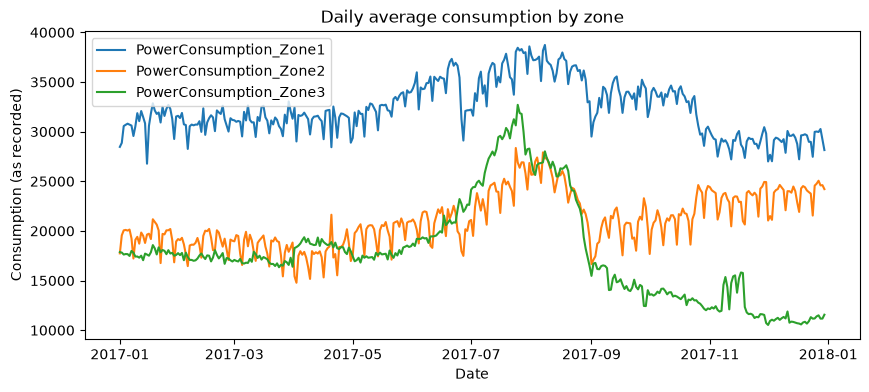

In [52]:
# Daily average consumption of each zone through the year, saved to the charts folder
import os
os.makedirs("charts", exist_ok=True)
daily = df.groupby("Date")[zones].mean()
daily.plot(figsize=(10, 4))
plt.title("Daily average consumption by zone")
plt.xlabel("Date")
plt.ylabel("Consumption (as recorded)")
plt.legend(loc="upper left")
plt.savefig("charts/01_daily_trend.png", dpi=150, bbox_inches="tight")
plt.show()

Zone 1 is the highest and steadiest zone all year. All zones rise in summer, but Zone 3 rises the most, peaking in late July, then falls steeply from September to about 11,000 by December. Zone 2 rises again in the last months of the year, while Zone 3 keeps falling.

### 5.2 Average consumption by zone (Seaborn)

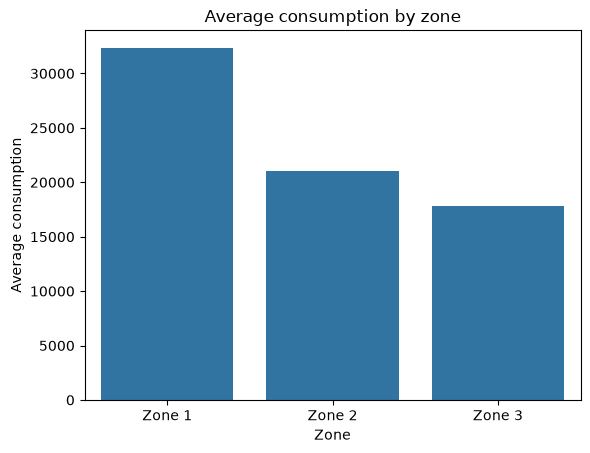

In [53]:
# Bar chart of the average consumption of each zone, saved to the charts folder
import seaborn as sns
avg = df[zones].mean().reset_index()
avg.columns = ["Zone", "Average consumption"]
avg["Zone"] = ["Zone 1", "Zone 2", "Zone 3"]
sns.barplot(data=avg, x="Zone", y="Average consumption")
plt.title("Average consumption by zone")
plt.savefig("charts/02_average_by_zone.png", dpi=150, bbox_inches="tight")
plt.show()

Zone 1 has the highest average consumption (about 32,300), followed by Zone 2 (about 21,000) and Zone 3 (about 17,800).

### 5.3 Hourly consumption pattern (Seaborn)

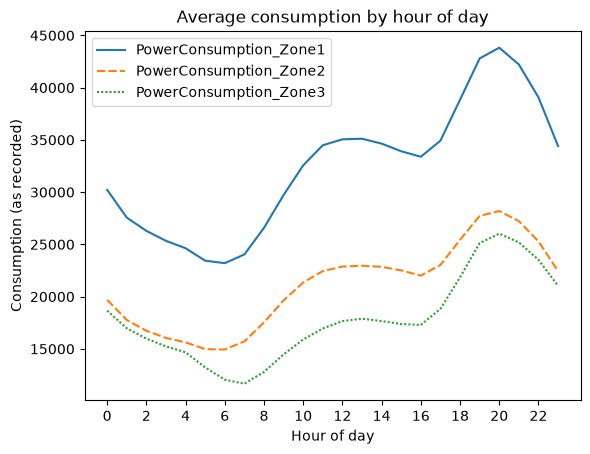

In [54]:
# Line chart of average consumption for each hour of the day, saved to the charts folder
sns.lineplot(data=hourly)
plt.title("Average consumption by hour of day")
plt.xlabel("Hour of day")
plt.ylabel("Consumption (as recorded)")
plt.xticks(range(0, 24, 2))
plt.savefig("charts/03_hourly_pattern.png", dpi=150, bbox_inches="tight")
plt.show()

All three zones follow the same daily shape: a low at about 6 to 7 AM, a rise through the morning to a midday plateau, a slight dip at about 4 PM, and a steep evening climb to a peak at 8 PM. Zone 3 has the largest evening rise relative to its own level.

### 5.4 Monthly consumption pattern (Matplotlib)

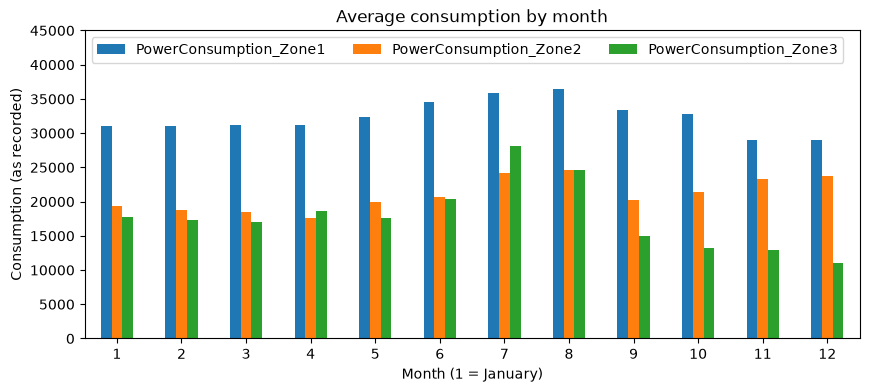

In [55]:
# Bar chart of average consumption for each month and zone, saved to the charts folder
monthly.plot(kind="bar", figsize=(10, 4))
plt.title("Average consumption by month")
plt.xlabel("Month (1 = January)")
plt.ylabel("Consumption (as recorded)")
plt.xticks(rotation=0)
plt.ylim(0, 45000)
plt.legend(loc="upper left", ncol=3)
plt.savefig("charts/04_monthly_pattern.png", dpi=150, bbox_inches="tight")
plt.show()

Consumption is highest in July and August in all three zones. Zone 3 peaks in July (about 28,200) and then falls each month to about 11,000 in December, while Zone 2 rises again in November and December. Zone 1 stays the highest zone in every month except July, where Zone 3 is next.

### 5.5 Day-of-week comparison (Plotly)

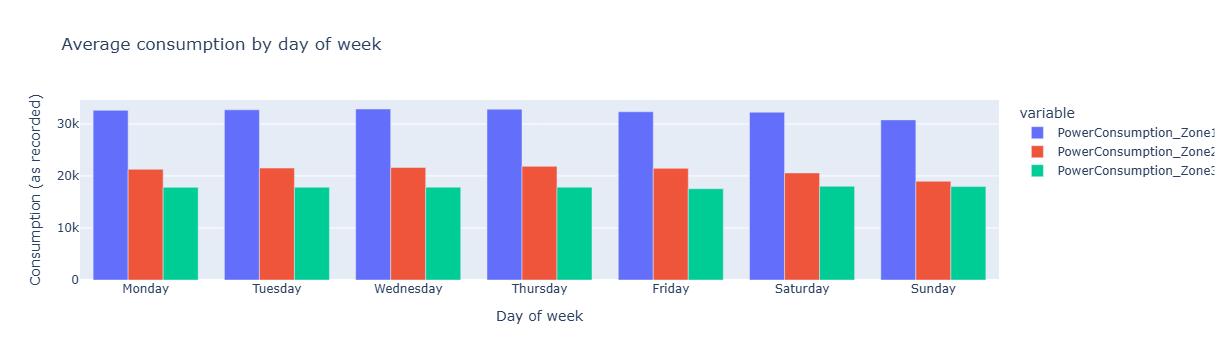

In [56]:
# Interactive bar chart of average consumption for each day of the week, saved as an HTML file
import plotly.express as px
fig = px.bar(weekly, barmode="group", title="Average consumption by day of week")
fig.update_layout(xaxis_title="Day of week", yaxis_title="Consumption (as recorded)")
fig.write_html("charts/05_day_of_week.html")
fig.show()

Monday to Friday are very similar in all three zones. Sunday is clearly lower in Zone 2 (about 19,000) and lower in Zone 1, while Zone 3 stays flat across the whole week.

### 5.6 Temperature and consumption (Seaborn)

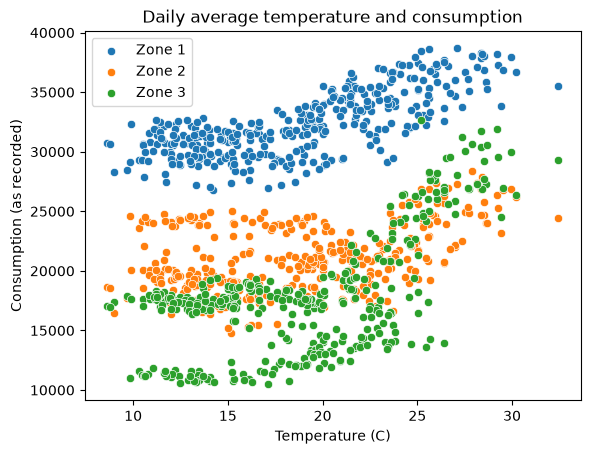

In [57]:
# Scatter chart of daily average temperature against each zone's consumption, saved to the charts folder
sns.scatterplot(data=daily_env, x="Temperature", y="PowerConsumption_Zone1", label="Zone 1")
sns.scatterplot(data=daily_env, x="Temperature", y="PowerConsumption_Zone2", label="Zone 2")
sns.scatterplot(data=daily_env, x="Temperature", y="PowerConsumption_Zone3", label="Zone 3")
plt.title("Daily average temperature and consumption")
plt.xlabel("Temperature (C)")
plt.ylabel("Consumption (as recorded)")
plt.savefig("charts/06_temperature_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

In all three zones, hotter days tend to have higher consumption. Zone 1 is the tightest and Zone 3 the most spread out. On days of similar temperature (10 to 20 C), Zone 3 has two separate groups, near 17,500 and near 11,000, which shows that temperature alone does not explain Zone 3. This is an association, not proof of cause.

### 5.7 Comparison of the three zones (Plotly)

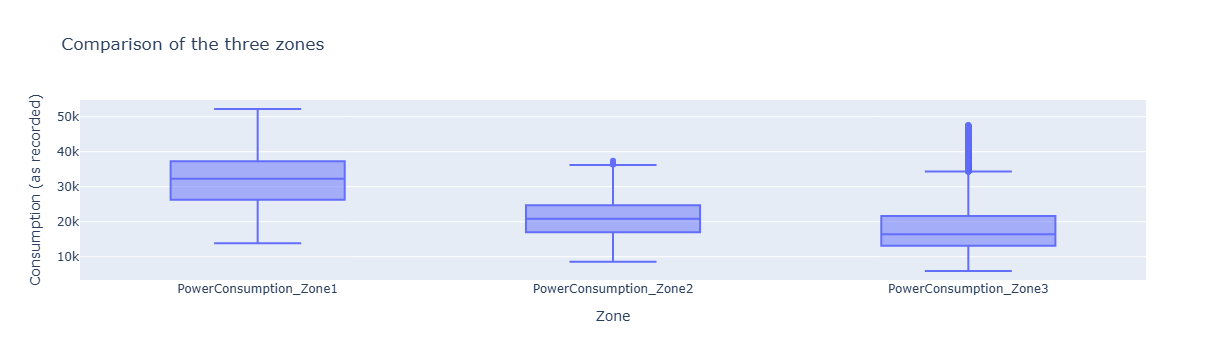

In [58]:
# Interactive box plot comparing the three zones, saved as an HTML file
fig = px.box(df, y=zones, title="Comparison of the three zones")
fig.update_layout(xaxis_title="Zone", yaxis_title="Consumption (as recorded)")
fig.write_html("charts/07_zone_comparison.html")
fig.show()

Zone 1 has the highest median consumption (about 32,000) and Zone 3 the lowest (about 16,000). Zone 3 has many readings far above its box, from the summer evening peaks, while Zone 2 has only a few and Zone 1 none.

### 1.8 Data-quality log

| Check | Result | Note |
|---|---|---|
| Rows and columns | 52,416 rows, 9 columns | Matches the brief |
| Missing values | None | No filling needed |
| Duplicate rows | None | |
| Duplicate timestamps | None | |
| Interval consistency | Every gap exactly 10 minutes, no readings missing | Data is complete and regular |
| Datetime format | Stored as text, month/day/year | Converted with an explicit format |
| Period covered | 1 Jan 2017 00:00 to 30 Dec 2017 23:50 | 31 Dec is not in the file (364 days) |
| Consumption unit | Dictionary says kWh | Size of values suggests average power, so values are reported as recorded |
| Diffuse flow columns | Described as emissions gases | Follow a daylight cycle, so not used for conclusions |
| Wind speed | 61% of readings near 0.08, 39% near 4.9, 0.2% between | Behaves like a two-state value that overlaps with summer |
| Extreme values | Zone 3 readings above 30,000 | All in June to August, a real summer pattern, so kept |
| Humidity unit | Not stated in the dictionary | Read as a percentage (assumption) |

## Task 6: Business Insights and Recommendations
### 6.1 Key findings

**1. Zone 1 carries the most load; Zone 3 is the hardest to predict.**
Zone 1 averages 32,345 (45% of the combined average), Zone 2 21,043 (30%) and Zone 3 17,835 (25%). Zone 3 is the most variable relative to its own level (0.37, against 0.22 and 0.25).
*What it means:* system load follows Zone 1, but forecasts for Zone 3 will be the least reliable.

**2. Demand peaks at 8 PM in every zone.**
The 8 PM average is 43,823 (Zone 1), 28,187 (Zone 2) and 26,028 (Zone 3). Consumption is lowest at 6 AM (Zones 1 and 2) or 7 AM (Zone 3), and rises by about 26%, 22% and 38% from 5 PM to 8 PM.
*What it means:* the 5 PM to 10 PM period is the most demanding window for supply and operations.

**3. July and August are the highest months, and Zone 3 swings the most.**
The highest month is August for Zones 1 and 2 and July for Zone 3. Zone 3 falls from 28,194 in July to 11,045 in December, about 2.5 times, while Zone 1 varies by only about 1.26 times.
*What it means:* summer needs its own planning scenario, especially for Zone 3.

**4. The week is flat apart from a Sunday dip in Zones 1 and 2.**
Sunday is about 12% below the average weekday in Zone 2 and about 6% below in Zone 1. Zone 3 shows no Sunday dip.
*What it means:* Sundays and the early-morning hours are natural low-demand windows for maintenance in Zones 1 and 2.

**5. Temperature has the strongest link with consumption.**
Correlation with temperature is 0.44, 0.38 and 0.49 on the raw readings, 0.73, 0.42 and 0.61 on daily averages, and stays positive (0.51, 0.33, 0.54) once the time of day is removed. In Zone 3, average consumption rises from 13,175 in the coolest band to 28,928 in the warmest.
*What it means:* temperature forecasts are a sensible input to demand forecasting. This is an association, not proof of cause, because temperature moves together with the season.

**6. Wind speed and the zones' late-year behaviour need caution.**
Wind speed behaves like a two-state value that is mostly in its high state in July and August, so its link with consumption largely reflects the season. Zone 2 also rises in November and December (23,240 and 23,682, against 19,394 in January) while Zones 1 and 3 fall.
*What it means:* wind data should be validated at source before it is used, and the late-year divergence between zones needs checking with the data owner.

### 6.2 Recommendations

**1. Plan operations and capacity around the evening ramp.**
Use the 8 PM average as the design point for each zone, and schedule supply, reserves and any demand-response measures for the 5 PM to 10 PM window (finding 2).

**2. Build a separate summer plan for July and August, led by Zone 3.**
Treat the summer high as a planning scenario of its own, and test temperature forecasts as an input to short-term demand forecasts on more years of data before relying on them (findings 3 and 5).

**3. Schedule maintenance in the low-demand windows.**
Use the early-morning hours (about 3 AM to 7 AM) and, in Zones 1 and 2, Sundays, because they carry the least demand and so the least disruption risk (findings 2 and 4).

**4. Investigate Zone 3 and Zone 2 in the last quarter of the year.**
Check metering, network changes and customer mix to explain why Zone 3 falls and Zone 2 rises while Zone 1 moves differently (finding 6).

**5. Fix the data foundations before building on them.**
Confirm with the data owner whether the consumption values are kWh per interval or average kW, correct the diffuse flow description, validate the wind sensor, and collect several years of data with holiday and calendar information (findings 5 and 6).

### 6.3 Limitations

- Only one year (364 days) of data, so seasonal behaviour cannot be separated from one-off events, and year-on-year change cannot be measured.
- The consumption unit is uncertain, so no absolute energy totals are reported.
- Correlations show association only. Temperature, season and time of day move together, and no holiday, tariff or industrial information is available.
- The diffuse flow columns are not interpreted because their description does not match how they behave.